# Full-wave response of lumped-element detectors

Displacement current changes a pickup's signal coupling and impedance as its size approaches the wavelength. This notebook follows those changes through a solenoid frequency sweep, radiation losses and scan sensitivity. The magnetoquasistatic (MQS) calculations are in the [lumped-element notebook](lumped_element.ipynb).

In [1]:
import math, tempfile, warnings
from contextlib import contextmanager
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import axionfem as af
from axionfem import scan, circuit as ck

print("axionFEM", af.__version__)
C_LIGHT = 299792458.0
RUNS = Path(tempfile.mkdtemp(prefix="axf_fullwave_"))   # solver run directories
plt.rcParams.update({"figure.dpi": 80, "font.size": 10, "axes.grid": True, "grid.color": "#e4e3df",
                     "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
                     "lines.linewidth": 1.8, "legend.frameon": False})
# one hue per topology
BLUE, ORANGE, GREEN, GOLD, VIOLET, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#6f6e69"
COL = {"toroid": BLUE, "solenoid": ORANGE, "core": GREEN}


def solve(design, tag, **kw):
    """Solve in RUNS/tag and report the number of unknowns and any solver warning."""
    r = design.solve(RUNS / tag, verbose=0, **kw)
    w = [x for x in (r.data.get("warnings") or []) if "background field is present" not in x]
    print(f"  {tag}: {r.data['mesh']['dofs']} DOFs" + (f", warnings: {w}" if w else ""))
    return r


@contextmanager
def quiet_loss_check():
    """Silence the warning of circuit.loss_interpolation_check (R_loss interpolated between two sweep rows is
    unreliable) inside this block; the intervals it flags for the solenoid sweep are printed after the sweep."""
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message=r".*R_loss interpolated between them is unreliable",
                                category=RuntimeWarning)
        yield

axionFEM 0.1.0


## Compare size with wavelength

The dimensionless size $kR$ is the outer radius times the vacuum wavenumber. Small values approach the magnetoquasistatic (MQS) limit.

In [2]:
print(f"{'m_a [neV]':>10}{'f [MHz]':>10}{'lambda [m]':>12}{'kR, R = 1 m':>13}{'R for kR = 0.1 [m]':>20}")
for m_neV in (0.5, 4.1, 10.0, 40.0, 100.0):
    f = scan.mass_to_freq(m_neV * 1e-9)
    lam = C_LIGHT / f
    print(f"{m_neV:10.1f}{f / 1e6:10.4g}{lam:12.4g}{2 * math.pi * 1.0 / lam:13.4f}{0.1 * lam / (2 * math.pi):20.3g}")

 m_a [neV]   f [MHz]  lambda [m]  kR, R = 1 m  R for kR = 0.1 [m]
       0.5    0.1209        2480       0.0025                39.5
       4.1    0.9914       302.4       0.0208                4.81
      10.0     2.418         124       0.0507                1.97
      40.0     9.672          31       0.2027               0.493
     100.0     24.18        12.4       0.5068               0.197


## Sweep the pickup response

The solenoid's coaxial pickup is driven by current $I$. Its electric field $\mathbf E_I$ overlaps the laboratory field $\mathbf B_{\rm lab}$ to give

$$
\Psi(\omega)=\frac{1}{i\omega I}\int\mathbf E_I\cdot\mathbf B_{\rm lab}\,dV.
$$

With time dependence $e^{-i\omega t}$, the impedance is

$$
Z(\omega)=R(\omega)-i\omega L(\omega).
$$

Here $R(\omega)$ is resistance. The `fullwave` block specifies frequencies in Hz; the default boundary lets radiation escape.

In [3]:
sol = af.template("solenoid")
print(sol.resolved_params())
res0 = solve(sol, "solenoid_mqs")
R_dev = res0.coupling["device_radius_m"]
print(f"MQS: Psi = {res0.Psi:.5e} H T m^2, L_p = {res0.L_p:.5e} H, device radius R = {R_dev:.3f} m")

# rows every 0.02 in kR from 0.42 to 0.58 resolve the copper loss in the band integrated in the last section
kR = np.unique(np.round(np.concatenate([np.geomspace(0.005, 0.6, 26), [0.1, 0.3, 0.6], np.linspace(0.42, 0.58, 9),
                                        np.linspace(0.62, 0.74, 7), [0.8, 1.0, 1.25]]), 6))
sol.doc["fullwave"] = {"frequencies": [float(k * C_LIGHT / (2 * math.pi * R_dev)) for k in kR], "modes": 3}
res = solve(sol, "solenoid_fw")
fw = res.data["fullwave"]
print({k: fw[k] for k in ("family", "boundary", "device_radius_m", "domain_radius_m", "exterior_term", "mesh_kh_max")})
print(f"{len(fw['sweep'])} frequencies, {fw['sweep'][0]['solver']['dofs']} DOFs")

{'H': 2.0, 'NI': 1000000.0, 'R': 1.0, 'g': 0.005, 'tc': 0.005, 'tp': 0.01, 'tw': 0.01, 'x': 0.534}
  solenoid_mqs: 73566 DOFs
MQS: Psi = 1.79714e-07 H T m^2, L_p = 2.45483e-07 H, device radius R = 1.010 m
  solenoid_fw: 73566 DOFs, warnings: ['full-wave: the readout is capacitive (L(omega) <= 0) at some frequencies, i.e. above its first self-resonance; F and Q_rad are omitted there']
{'family': 'TM0 (azimuthal H; poloidal readout current)', 'boundary': 'radiation', 'device_radius_m': 1.01, 'domain_radius_m': 3.553255549492606, 'exterior_term': 'included', 'mesh_kh_max': 0.09935667143785512}
47 frequencies, 73566 DOFs


`fullwave_tables` returns sorted frequency arrays. `Psi_SI` is the coupling magnitude in $\mathrm{H}\,\mathrm{T}\,\mathrm{m}^2$, `L_H` the inductance in H, and the resistance columns separate radiation from material losses.

`fullwave_tables`, `pickup_impedance` and the reach functions interpolate the copper loss `R_loss` log-log between the sweep rows, and `circuit.loss_interpolation_check` warns where that interpolation is unreliable. The cell prints the intervals it flags for this sweep: they lie next to the first self-resonance, above the bands that the calculations below use (kR ≤ 0.5). The calls on the sweep run inside `quiet_loss_check` (defined in the first cell), which silences that warning.

In [4]:
with quiet_loss_check():
    tab = ck.fullwave_tables(res.data)
rows = {round(float(k), 6): i for i, k in enumerate(tab["k_R"])}
# docs/validation/fullwave.md, "solenoid" table: kR -> (|Psi|/Psi_MQS - 1, L/L_MQS - 1, R_rad [ohm])
DOC_SOL = {0.1: (2.58e-02, 1.81e-02, 6.83e-06), 0.3: (2.76e-01, 1.95e-01, 7.75e-03), 0.6: (3.04e+00, 2.33e+00, 4.85e+00)}
print(f"{'kR':>6}{'f [MHz]':>9}{'|Psi|/Psi_MQS-1':>17}{'(doc)':>10}{'L/L_MQS-1':>12}{'(doc)':>10}{'R_rad [ohm]':>13}{'(doc)':>10}")
for k, (dp, dl, rr) in DOC_SOL.items():
    i = rows[k]
    print(f"{k:6.2f}{tab['f_Hz'][i] / 1e6:9.3f}{tab['Psi_over_MQS'][i] - 1:17.3e}{dp:10.2e}{tab['L_over_MQS'][i] - 1:12.3e}"
          f"{dl:10.2e}{tab['R_rad_ohm'][i]:13.3e}{rr:10.2e}")
pb = max(r["power_balance_rel"] for r in fw["sweep"])
print(f"power balance |Re Z/2 - P_rad| (relative), worst over the sweep: {pb:.1e}")
with quiet_loss_check():
    flagged = ck.loss_interpolation_check(fw["sweep"])
to_kR = lambda f: 2 * math.pi * f * R_dev / C_LIGHT
print("R_loss interpolation flagged between the rows at kR =",
      ", ".join(f"{to_kR(a):.3f}-{to_kR(b):.3f}" for a, b in flagged) or "none")

    kR  f [MHz]  |Psi|/Psi_MQS-1     (doc)   L/L_MQS-1     (doc)  R_rad [ohm]     (doc)
  0.10    4.724        2.576e-02  2.58e-02   1.813e-02  1.81e-02    6.833e-06  6.83e-06
  0.30   14.172        2.760e-01  2.76e-01   1.955e-01  1.95e-01    7.755e-03  7.75e-03
  0.60   28.345        3.038e+00  3.04e+00   2.328e+00  2.33e+00    4.851e+00  4.85e+00
power balance |Re Z/2 - P_rad| (relative), worst over the sweep: 6.0e-12
R_loss interpolation flagged between the rows at kR = 0.560-0.580, 0.580-0.600, 0.600-0.620, 0.620-0.640, 0.640-0.660, 0.660-0.680, 0.680-0.700


The plots show departure from MQS and the first pickup self-resonance. Past the pole, negative inductance means a series capacitor cannot tune the pickup.

low-kR fit: |Psi|/Psi_MQS - 1 = 2.5259 (kR)^2,  L/L_MQS - 1 = 1.7775 (kR)^2
log-log slopes at kR <= 0.03: 2.0008 (Psi), 2.0008 (L)
first self-resonance between 33.07 and 34.01 MHz; zero of 1/L at 33.47 MHz (kR = 0.708)
quarter-wave stub: c/4H = 37.47 MHz (-10.7%); with the open-end extension 0.55 x gap (0.254 m, validation page for published benchmarks, Sec. 6.1): 33.26 MHz (+0.6%)
closed-sphere TM0 eigenmodes (a shielded room of radius 3.55 m):
   f =   29.92 MHz, kR = 0.633, energy fraction {'air': 0.9973484896981962, 'port': 0.0001518444141800886, 'winding': 0.0024996658876231376}
   f =   34.26 MHz, kR = 0.725, energy fraction {'air': 0.9994457165086665, 'port': 0.00014931180351401843, 'winding': 0.0004049716878187296}
   f =   51.22 MHz, kR = 1.084, energy fraction {'air': 0.9995981548593286, 'port': 2.9992213789492372e-05, 'winding': 0.00037185292688205385}


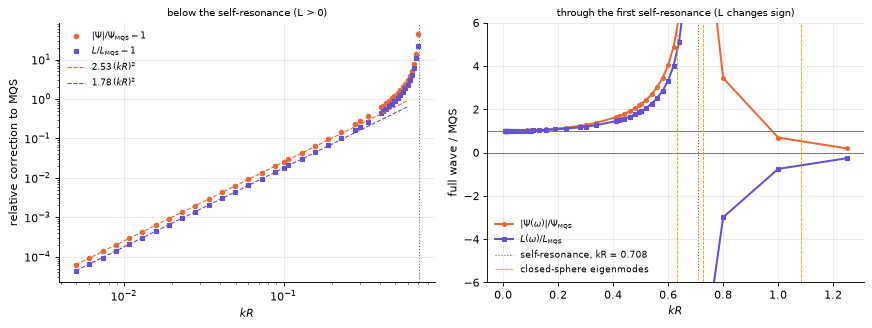

In [5]:
k, f = tab["k_R"], tab["f_Hz"]
dpsi, dL = tab["Psi_over_MQS"] - 1, tab["L_over_MQS"] - 1
low = k <= 0.03
a_psi = np.exp(np.mean(np.log(dpsi[low] / k[low] ** 2)))     # coefficient of (kR)^2, fitted at low kR
a_L = np.exp(np.mean(np.log(dL[low] / k[low] ** 2)))
print(f"low-kR fit: |Psi|/Psi_MQS - 1 = {a_psi:.4f} (kR)^2,  L/L_MQS - 1 = {a_L:.4f} (kR)^2")
print(f"log-log slopes at kR <= 0.03: {np.polyfit(np.log(k[low]), np.log(dpsi[low]), 1)[0]:.4f} (Psi), "
      f"{np.polyfit(np.log(k[low]), np.log(dL[low]), 1)[0]:.4f} (L)")

j = int(np.argmax(tab["L_H"] <= 0))                         # first row above the self-resonance
x0, x1, y0, y1 = f[j - 1], f[j], 1 / tab["L_H"][j - 1], 1 / tab["L_H"][j]
f_sr = x0 - y0 * (x1 - x0) / (y1 - y0)
kR_sr = 2 * math.pi * f_sr * R_dev / C_LIGHT
print(f"first self-resonance between {f[j - 1] / 1e6:.2f} and {f[j] / 1e6:.2f} MHz; zero of 1/L at "
      f"{f_sr / 1e6:.2f} MHz (kR = {kR_sr:.3f})")
p = sol.resolved_params()
ell, gap = p["H"], (p["R"] - p["g"]) - p["x"] * p["R"]            # coax length and gap r_o - r_i (template geometry)
f_qw, f_oe = C_LIGHT / (4 * ell), C_LIGHT / (4 * (ell + 0.55 * gap))
print(f"quarter-wave stub: c/4H = {f_qw / 1e6:.2f} MHz ({f_sr / f_qw - 1:+.1%}); with the open-end extension 0.55 x gap "
      f"({0.55 * gap:.3f} m, validation page for published benchmarks, Sec. 6.1): {f_oe / 1e6:.2f} MHz ({f_sr / f_oe - 1:+.1%})")
eig = fw["eigenmodes"]["TM"]["modes"]
print("closed-sphere TM0 eigenmodes (a shielded room of radius", f"{fw['domain_radius_m']:.2f} m):")
for m in eig:
    print(f"   f = {m['f_Hz'] / 1e6:7.2f} MHz, kR = {m['k_R']:.3f}, energy fraction {m['energy_fraction']}")

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4.2))
below = tab["L_H"] > 0
ax0.loglog(k[below], dpsi[below], "o", ms=4, color=ORANGE, label=r"$|\Psi|/\Psi_{\rm MQS}-1$")
ax0.loglog(k[below], dL[below], "s", ms=4, color=VIOLET, label=r"$L/L_{\rm MQS}-1$")
kk = np.geomspace(k[0], 0.6, 50)
ax0.loglog(kk, a_psi * kk ** 2, color=ORANGE, lw=1, ls="--", label=rf"${a_psi:.2f}\,(kR)^2$")
ax0.loglog(kk, a_L * kk ** 2, color=VIOLET, lw=1, ls="--", label=rf"${a_L:.2f}\,(kR)^2$")
ax0.axvline(kR_sr, color=GREY, lw=1, ls=":")
ax0.set_xlabel("$kR$"); ax0.set_ylabel("relative correction to MQS"); ax0.legend(fontsize=8)
ax0.set_title("below the self-resonance (L > 0)", fontsize=9)
for part, lab in ((k < kR_sr, True), (k > kR_sr, False)):      # no line across the pole
    ax1.plot(k[part], tab["Psi_over_MQS"][part], "o-", ms=3.5, color=ORANGE,
             label=r"$|\Psi(\omega)|/\Psi_{\rm MQS}$" if lab else None)
    ax1.plot(k[part], tab["L_over_MQS"][part], "s-", ms=3.5, color=VIOLET, label=r"$L(\omega)/L_{\rm MQS}$" if lab else None)
ax1.axhline(1, color=GREY, lw=0.8); ax1.axhline(0, color=GREY, lw=0.8)
ax1.axvline(kR_sr, color=GREY, lw=1, ls=":", label=f"self-resonance, kR = {kR_sr:.3f}")
for m in eig:
    ax1.axvline(m["k_R"], color=GOLD, lw=0.8, ls="--")
ax1.plot([], [], color=GOLD, lw=0.8, ls="--", label="closed-sphere eigenmodes")
ax1.set_ylim(-6, 6); ax1.set_xlabel("$kR$"); ax1.set_ylabel("full wave / MQS"); ax1.legend(fontsize=8, loc="lower left")
ax1.set_title("through the first self-resonance (L changes sign)", fontsize=9)
fig.tight_layout(); plt.show()

Dashed eigenmode markers describe a closed conducting sphere; the sweep uses an open boundary.

## Compare radiation and material loss

The unshielded toroid radiates through its azimuthal pickup. Compare its radiation quality factor with the solenoid's radiation and copper-loss curves; smaller quality factors indicate stronger damping.

  toroid_mqs: 86051 DOFs
  toroid_fw: 86051 DOFs
toroid: R = 2.040 m, family TE0 (azimuthal E; azimuthal readout current), Psi_MQS = 3.0810e-07 H T m^2, L_p = 1.4860e-06 H
  kR = 0.10: dPsi +2.642e-03 (doc +2.64e-03), dL +2.531e-03 (doc +2.53e-03), R_rad 3.767e-03 (doc 3.77e-03)
  kR = 0.30: dPsi +2.307e-02 (doc +2.31e-02), dL +2.205e-02 (doc +2.20e-02), R_rad 2.933e-01 (doc 2.93e-01)
  kR = 1.00: dPsi +2.110e-01 (doc +2.11e-01), dL +1.913e-01 (doc +1.91e-01), R_rad 2.693e+01 (doc 2.69e+01)
R_rad ~ (kR)^n at kR <= 0.05: n = 4.000 (toroid), 6.005 (solenoid)
toroid Q_rad = 2e+07 (optimistic benchmark Q) at kR = 0.0066, f = 155 kHz
toroid Q_rad = 1e+06 (conservative benchmark Q) at kR = 0.0179, f = 419 kHz


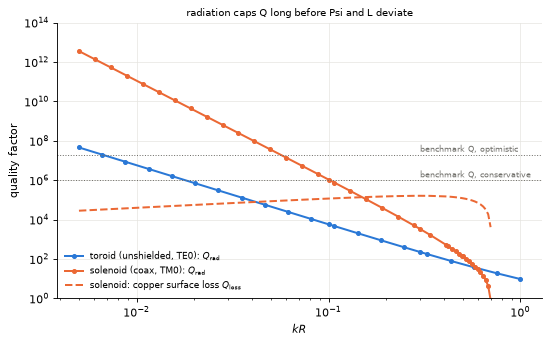

In [6]:
tor = af.template("toroid")
rt0 = solve(tor, "toroid_mqs")
R_tor = rt0.coupling["device_radius_m"]
kR_t = np.unique(np.round(np.concatenate([np.geomspace(0.005, 1.0, 20), [0.1, 0.3, 1.0]]), 6))
tor.doc["fullwave"] = {"frequencies": [float(x * C_LIGHT / (2 * math.pi * R_tor)) for x in kR_t]}
rt = solve(tor, "toroid_fw")
tab_t = ck.fullwave_tables(rt.data)
print(f"toroid: R = {R_tor:.3f} m, family {rt.data['fullwave']['family']}, Psi_MQS = {rt0.Psi:.4e} H T m^2, "
      f"L_p = {rt0.L_p:.4e} H")
# docs/validation/fullwave.md, "toroid" table: kR -> (|Psi|/Psi_MQS - 1, L/L_MQS - 1, R_rad [ohm])
DOC_TOR = {0.1: (2.64e-03, 2.53e-03, 3.77e-03), 0.3: (2.31e-02, 2.20e-02, 2.93e-01), 1.0: (2.11e-01, 1.91e-01, 2.69e+01)}
rows_t = {round(float(x), 6): i for i, x in enumerate(tab_t["k_R"])}
for x, (dp, dl, rr) in DOC_TOR.items():
    i = rows_t[x]
    print(f"  kR = {x:4.2f}: dPsi {tab_t['Psi_over_MQS'][i] - 1:+.3e} (doc {dp:+.2e}), dL {tab_t['L_over_MQS'][i] - 1:+.3e} "
          f"(doc {dl:+.2e}), R_rad {tab_t['R_rad_ohm'][i]:.3e} (doc {rr:.2e})")

def slope(t, kmax=0.05):
    s = (t["k_R"] <= kmax) & (t["L_H"] > 0)
    return np.polyfit(np.log(t["k_R"][s]), np.log(t["R_rad_ohm"][s]), 1)[0]
print(f"R_rad ~ (kR)^n at kR <= 0.05: n = {slope(tab_t):.3f} (toroid), {slope(tab):.3f} (solenoid)")

def Q_of(t):
    w = 2 * math.pi * t["f_Hz"]
    return w * t["L_H"] / t["R_rad_ohm"], (w * t["L_H"] / t["R_loss_ohm"] if np.any(t["R_loss_ohm"] > 0) else None)
Qr_t, _ = Q_of(tab_t)
Qr_s, Ql_s = Q_of(tab)
for Qb, name in ((2e7, "optimistic"), (1e6, "conservative")):
    x = np.interp(np.log(Qb), np.log(Qr_t[::-1]), np.log(tab_t["k_R"][::-1]))
    print(f"toroid Q_rad = {Qb:.0e} ({name} benchmark Q) at kR = {math.exp(x):.4f}, f = "
          f"{math.exp(x) * C_LIGHT / (2 * math.pi * R_tor) / 1e3:.0f} kHz")

fig, ax = plt.subplots(figsize=(7, 4.4))
ok_s = tab["L_H"] > 0
ax.loglog(tab_t["k_R"], Qr_t, "o-", ms=3.5, color=BLUE, label="toroid (unshielded, TE0): $Q_{\\rm rad}$")
ax.loglog(tab["k_R"][ok_s], Qr_s[ok_s], "o-", ms=3.5, color=ORANGE, label="solenoid (coax, TM0): $Q_{\\rm rad}$")
ax.loglog(tab["k_R"][ok_s], Ql_s[ok_s], "--", color=ORANGE, label="solenoid: copper surface loss $Q_{\\rm loss}$")
for Qb, lab in ((2e7, "optimistic"), (1e6, "conservative")):
    ax.axhline(Qb, color=GREY, lw=0.9, ls=":")
    ax.text(0.3, Qb * 1.4, f"benchmark Q, {lab}", fontsize=7.5, color=GREY)
ax.set_xlabel("$kR$"); ax.set_ylabel("quality factor"); ax.set_ylim(1, 1e14); ax.legend(fontsize=8, loc="lower left")
ax.set_title("radiation caps Q long before Psi and L deviate", fontsize=9)
fig.tight_layout(); plt.show()

## Pass the sweep to a circuit

`pickup_impedance` and `pickup_coupling` supply frequency-dependent inputs to `series_readout`. The tuned circuit's effective inductance includes dispersion; it differs from the reactive inductance in the sweep.

In [7]:
with quiet_loss_check():
    Z_fw = ck.pickup_impedance(res.data, model="fullwave")
    Psi_fw = ck.pickup_coupling(res.data)
NOISE = {"T": 0.030, "eta_A": 10.0}       # 30 mK, eta_A = 10 (the conservative benchmark's T and amplifier)
f_lo, f_hi = (x * C_LIGHT / (2 * math.pi * R_dev) for x in (0.02, 0.3))
with quiet_loss_check():
    rf_log = scan.reach_fullwave(res.data, NOISE, allocation="log_uniform", f_min=f_lo, f_max=f_hi, n=61)

print(f"{'kR':>6}{'f [MHz]':>9}{'L(w)/L_p':>10}{'L_eff/L_p (circuit)':>21}{'(reach_fullwave)':>18}{'Q (circuit)':>13}"
      f"{'(reach_fullwave)':>18}{'|Psi(w)|/Psi':>14}")
for x in (0.05, 0.15, 0.25):
    f0 = x * C_LIGHT / (2 * math.pi * R_dev)
    ro = ck.series_readout(Z_p=Z_fw, Psi_SI=Psi_fw, L_p_H=res0.L_p, f_Hz=f0, T_K=NOISE["T"], eta_A=NOISE["eta_A"])
    eq = ro.equivalent(f_Hz=f0)
    w = 2 * math.pi * f0
    lf = np.log(rf_log["f_Hz"])
    Le_r = np.interp(np.log(f0), lf, rf_log["L_eff_H"])
    Q_r = np.exp(np.interp(np.log(f0), lf, np.log(rf_log["Q"])))
    print(f"{x:6.2f}{f0 / 1e6:9.3f}{-Z_fw(w).imag / w / res0.L_p:10.4f}{eq['L_eff_H'] / res0.L_p:21.4f}{Le_r / res0.L_p:18.4f}"
          f"{eq['Q_loaded']:13.5g}{Q_r:18.5g}{eq['scan_inputs']['Psi_SI_H_T_m2'] / res0.Psi:14.4f}")

    kR  f [MHz]  L(w)/L_p  L_eff/L_p (circuit)  (reach_fullwave)  Q (circuit)  (reach_fullwave)  |Psi(w)|/Psi
  0.05    2.362    1.0045               1.0099            1.0090        86571             86477        1.0064
  0.15    7.086    1.0425               1.0821            1.0859        69590             69831        1.0603
  0.25   11.810    1.1306               1.2833            1.2726       9823.7            9741.5        1.1842


`reach_fullwave` uses the sweep's coupling, tuned inductance and losses. Here the supplied noise model adds no intrinsic loss beyond copper and radiation, and both baths share a temperature. Target allocation follows the DFSZ coupling curve; log-uniform allocation spends equal time per octave.

band 0.945-14.172 MHz; sweep rows used [42, 47] (the rest are above the self-resonance); Q_other = None, T_rad assumed equal to the bath: True
local-validity checks: noise bandwidth/f <= 0.0041 (limit 0.1), log variation x bandwidth <= 0.0197 (limit 0.05)
target allocation: g95(full wave)/g95(MQS) = 0.9990 (spread 5.6e-16)
  f [MHz]     kR  F/F_MQS  Q (full wave)  Q (MQS, copper)  g95 ratio
    0.945  0.020   1.0013          55967            55888     0.9993
    2.330  0.049   1.0074          85950            85403     0.9966
    5.747  0.122   1.0474          97189       1.2401e+05     1.0506
    9.025  0.191   1.1138          33023       1.3997e+05     1.3967
   14.172  0.300   1.2878         3962.5       1.3596e+05     2.2719


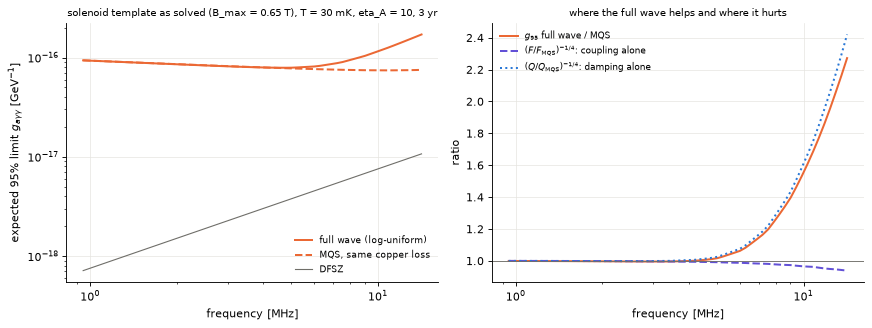

In [8]:
with quiet_loss_check():
    rf_tgt = scan.reach_fullwave(res.data, NOISE, allocation="target", f_min=f_lo, f_max=f_hi, n=61)
b = rf_log["band"]
print(f"band {b['f_min_Hz'] / 1e6:.3f}-{b['f_max_Hz'] / 1e6:.3f} MHz; sweep rows used {b['sweep_rows_used']} (the rest are "
      f"above the self-resonance); Q_other = {b['Q_other']}, "
      f"T_rad assumed equal to the bath: {b['radiation_temperature_assumed_equal']}")
print(f"local-validity checks: noise bandwidth/f <= {b['noise_bandwidth_over_f_max']:.4f} (limit 0.1), "
      f"log variation x bandwidth <= {b['local_variation_bound']:.4f} (limit 0.05)")
print(f"target allocation: g95(full wave)/g95(MQS) = {np.median(rf_tgt['ratio_g95_fullwave_over_mqs']):.4f} "
      f"(spread {np.ptp(rf_tgt['ratio_g95_fullwave_over_mqs']):.1e})")
print(f"{'f [MHz]':>9}{'kR':>7}{'F/F_MQS':>9}{'Q (full wave)':>15}{'Q (MQS, copper)':>17}{'g95 ratio':>11}")
kRm = 2 * math.pi * rf_log["f_Hz"] * R_dev / C_LIGHT
for i in (0, 20, 40, 50, 60):
    print(f"{rf_log['f_Hz'][i] / 1e6:9.3f}{kRm[i]:7.3f}{rf_log['ratio_F_fullwave_over_mqs'][i]:9.4f}{rf_log['Q'][i]:15.5g}"
          f"{rf_log['mqs']['Q'][i]:17.5g}{rf_log['ratio_g95_fullwave_over_mqs'][i]:11.4f}")

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4.2))
fM = rf_log["f_Hz"] / 1e6
ax0.loglog(fM, rf_log["g95_GeV"], color=ORANGE, label="full wave (log-uniform)")
ax0.loglog(fM, rf_log["mqs"]["g95_GeV"], color=ORANGE, ls="--", label="MQS, same copper loss")
ax0.loglog(fM, rf_log["g_target_GeV"], color=GREY, lw=1, label="DFSZ")
ax0.set_xlabel("frequency [MHz]"); ax0.set_ylabel(r"expected 95% limit $g_{a\gamma\gamma}$ [GeV$^{-1}$]")
ax0.set_title(f"solenoid template as solved (B_max = {res0.B_max:.2f} T), T = 30 mK, eta_A = 10, 3 yr", fontsize=9)
ax0.legend(fontsize=8)
ax1.semilogx(fM, rf_log["ratio_g95_fullwave_over_mqs"], color=ORANGE, label="$g_{95}$ full wave / MQS")
ax1.semilogx(fM, rf_log["ratio_F_fullwave_over_mqs"] ** -0.25, color=VIOLET, ls="--",
             label=r"$(F/F_{\rm MQS})^{-1/4}$: coupling alone")
ax1.semilogx(fM, (rf_log["Q"] / rf_log["mqs"]["Q"]) ** -0.25, color=BLUE, ls=":",
             label=r"$(Q/Q_{\rm MQS})^{-1/4}$: damping alone")
ax1.axhline(1, color=GREY, lw=0.8); ax1.set_xlabel("frequency [MHz]"); ax1.set_ylabel("ratio")
ax1.set_title("where the full wave helps and where it hurts", fontsize=9); ax1.legend(fontsize=8)
fig.tight_layout(); plt.show()

A reach ratio above one means worse sensitivity than MQS. The local scan approximation requires a narrow sensitivity band and slowly varying response; the next cell shows when it raises an error.

In [9]:
def try_reach(results, bench, **kw):
    try:
        with quiet_loss_check():
            r = scan.reach_fullwave(results, bench, allocation="log_uniform", n=41, **kw)
        q = r["ratio_g95_fullwave_over_mqs"]
        return f"OK: g95 ratio {q.min():.3f}-{q.max():.3f}, noise bandwidth/f <= {r['band']['noise_bandwidth_over_f_max']:.3g}"
    except ValueError as e:
        return f"refused: {e}"

to_f = lambda x, R: x * C_LIGHT / (2 * math.pi * R)
print("solenoid, kR 0.02-0.45:", try_reach(res.data, NOISE, f_min=to_f(0.02, R_dev), f_max=to_f(0.45, R_dev)))
print("solenoid, whole positive-L sweep:", try_reach(res.data, NOISE))
print("toroid, conservative (Q_other = 1e6), kR 0.02-0.3:",
      try_reach(rt.data, "conservative", f_min=to_f(0.02, R_tor), f_max=to_f(0.3, R_tor)))
print("toroid, conservative, kR 0.02-0.1:",
      try_reach(rt.data, "conservative", f_min=to_f(0.02, R_tor), f_max=to_f(0.1, R_tor)))

solenoid, kR 0.02-0.45: refused: local noise bandwidth/variation guard failed at 21258469 Hz: width/f=0.0226119 (limit 0.1), logarithmic variation=0.120305 (limit 0.05); use scan.finite_band with the tuned circuit
solenoid, whole positive-L sweep: refused: pole slope changes by more than 5% between interpolants; refine the full-wave sweep or use finite_band
toroid, conservative (Q_other = 1e6), kR 0.02-0.3: refused: local noise bandwidth/variation guard failed at 7016684.1 Hz: width/f=0.133064 (limit 0.1), logarithmic variation=0.37897 (limit 0.05); use scan.finite_band with the tuned circuit
toroid, conservative, kR 0.02-0.1: OK: g95 ratio 1.244-3.624, noise bandwidth/f <= 0.016


## Integrate a broad response

`finite_band` integrates each tuned circuit's noise and returns a minimum-time schedule. Compare the times from 40 and 80 settings to assess frequency sampling.

In [10]:
make_fw = lambda f0: ck.series_readout(Z_p=Z_fw, Psi_SI=Psi_fw, L_p_H=res0.L_p, f_Hz=f0, T_K=0.030, eta_A=10.0)
fa, fb = to_f(0.4, R_dev), to_f(0.5, R_dev)
YEAR = 3.15576e7
for ns in (40, 80):
    plan = scan.finite_band(make_fw, fa, fb, n_settings=ns, n_targets=ns)
    c = plan["comparison"]
    print(f"full wave, exact N_V, {ns} settings: LP live time to reach DFSZ = {plan['schedule']['t_total_s'] / YEAR:.5g} yr")
    if ns == 40:
        t40 = plan["schedule"]["t_total_s"]
print(f"40 -> 80 settings: relative change {plan['schedule']['t_total_s'] / t40 - 1:+.1e}")
print(f"single pole vs exact (80 settings): worst kernel deviation {100 * c['kernel_max_rel_dev']:.0f} %, the pole's own plan "
      f"covers only {c['min_coverage_of_reduced_schedule']:.3f} of Theta")

mqs = scan.reach_dispersive(tab["f_Hz"], res0.Psi, res0.L_p, R_ohm=tab["R_loss_ohm"], T_K=0.030, eta_A=10.0,
                            f_min=fa, f_max=fb, n=41)
t_mqs = 3.0 * np.median(mqs["g95_GeV"] / mqs["g_target_GeV"]) ** 4          # target allocation: t = 3 yr (g95/g_DFSZ)^4
print(f"MQS, local scan, same copper loss: time to reach DFSZ = {t_mqs:.4g} yr "
      f"(noise bandwidth/f = {mqs['band']['noise_bandwidth_over_f_max']:.1e})")
ratio_t = plan["schedule"]["t_total_s"] / YEAR / t_mqs
print(f"full wave / MQS live time = {ratio_t:.1f}  ->  equivalent factor in g: {ratio_t ** 0.25:.2f}")

full wave, exact N_V, 40 settings: LP live time to reach DFSZ = 22480 yr
full wave, exact N_V, 80 settings: LP live time to reach DFSZ = 22441 yr
40 -> 80 settings: relative change -1.7e-03
single pole vs exact (80 settings): worst kernel deviation 42 %, the pole's own plan covers only 0.975 of Theta
MQS, local scan, same copper loss: time to reach DFSZ = 193.6 yr (noise bandwidth/f = 1.5e-04)
full wave / MQS live time = 115.9  ->  equivalent factor in g: 3.28


`schedule["t_total_s"]` is the time needed to cover the target masses; `comparison` measures the single-pole approximation's error.

This axisymmetric model assumes uniform feeding around the axis; a localized feed requires a 3D check near resonance. Refine the mesh and frequency sweep before using quantitative results.

Continue with [readout circuits and SQUID chains](readout_squid.ipynb), the [full-wave validation](../docs/validation/fullwave.md) or the [scan guide](../docs/physics/scan_and_signal.md).